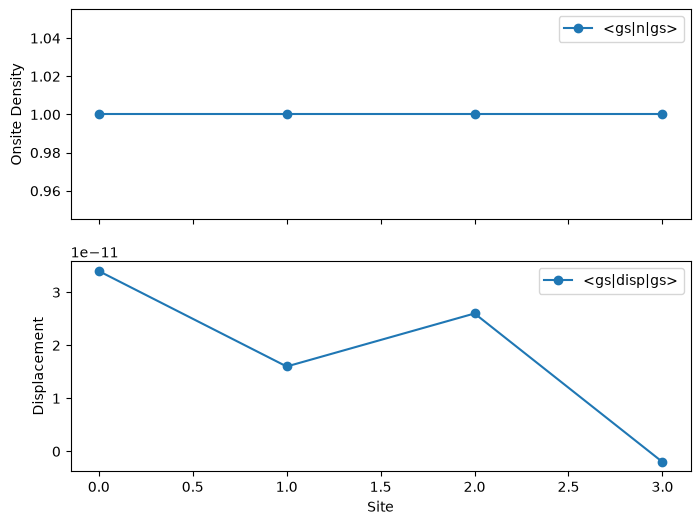

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# This script is used to plot the onsite density 

cout_file = '/Users/qqt/Documents/r_b1g_phonon/data/2026_october/29_test_scripts/N=4_Nup=2_Ndown=2_20261029_183053/runForinput_N=4_Nup=2_Ndown=2_20261029_183053.cout'

GS_OPERATOR_LABEL_n = "<gs|n|gs>"
GS_OPERATOR_LABEL_disp = "<gs|disp|gs>"

"""
 Read the line from the file which is of the form
1 1.000000000000 0.000000000000 <gs|n|gs> 1.000000000000
site, real_value, imag_value, label, <gs|gs>
"""

def read_onsite_values(file_path, operator_label):
    values_by_site = {}

    with open(file_path) as file:
        for line in file:
            fields = line.split()
            if operator_label in fields:
                site = float(fields[0])
                value = float(fields[1])
                values_by_site[site] = value

    if not values_by_site:
        raise ValueError(f"No rows found for {operator_label!r}")

    sites = sorted(values_by_site)
    values = [values_by_site[site] for site in sites]
    return sites, values


sites, n_values = read_onsite_values(cout_file, GS_OPERATOR_LABEL_n)
sites, disp_values = read_onsite_values(cout_file, GS_OPERATOR_LABEL_disp)

fig, ax = plt.subplots(2,1, figsize=(8, 6), sharex=True)
ax[0].plot(sites, n_values, marker='o', label=GS_OPERATOR_LABEL_n)
ax[0].set_ylabel("Onsite Density")
ax[0].legend()
ax[1].plot(sites, disp_values, marker='o', label=GS_OPERATOR_LABEL_disp)
ax[1].set_ylabel("Displacement")
ax[1].set_xlabel("Site")
ax[1].legend()
plt.show()